# Linear basal sliding-law test

This notebook tests whether the two steady full-Stokes fold examples survive when basal speed is determined by shear stress rather than prescribed. The bed geometries, ice thickness, viscosity, surface slope, surface-deposition construction and direct fold test are unchanged. Length is in m, time in yr, velocity in m yr$^{-1}$, stress in Pa and mobility in m yr$^{-1}$ Pa$^{-1}$.

The observational prediction is explicit: a stress-law realization of either recumbent fold must produce $\partial x/\partial x_0<0$ between surface deposition and re-emergence.

## Equations, assumptions and boundary conditions

The ice is incompressible and linear viscous,

$$-\nabla\cdot\left[2\eta\,\mathrm{sym}(\nabla\mathbf{u})-p\mathbf{I}\right]=\rho\mathbf{g},\qquad \nabla\cdot\mathbf{u}=0.$$

At the fixed bed, the signed tangential speed is proportional to resisting shear stress,

$$u_t=C\tau_b,\qquad u_n=0,\qquad \tau_b=-\mathbf{t}\cdot\boldsymbol{\sigma}\mathbf{n}.$$

Thus the bed can only remove mechanical energy: its power is $-\int \tau_bu_t\,\mathrm{d}s\leq0$. No penetration is imposed with symmetric Nitsche terms. The root-mean-square normal-velocity residual and a three-mesh sign check are reported below.

The mobility sweep is $C=0.5\times10^{-6}$ to $10\times10^{-6}$. For comparison, a flat 160 m slab has driving stress $\tau_d=\rho gH\sin\theta=43.2$ kPa and sliding speed $C\tau_d$. A flat-bed solve checks the implementation against this analytical result.

The flat-bed driving stress is 43173.2 Pa.


Flat-bed validation at C=4.6e-6 m yr-1 Pa-1: FEM=0.198596809 m yr-1, exact=0.198596809 m yr-1, relative error=-3.90e-13.
Solving prescribed-velocity controls.


Solving the linear sliding-law mobility sweep.
  persistent extrusion, C=5.0e-07 m yr-1 Pa-1


  persistent extrusion, C=1.0e-06 m yr-1 Pa-1


  persistent extrusion, C=2.0e-06 m yr-1 Pa-1


  persistent extrusion, C=4.6e-06 m yr-1 Pa-1


... (12 outputs left out)

  slow-flow amplification, mesh 64 x 14


  slow-flow amplification, mesh 96 x 21


  slow-flow amplification, mesh 128 x 28


,case,mesh,minimum dx/dx0,age of minimum,mean bed x speed,rms normal speed
0,persistent extrusion,64 x 14,0.875046,22500,0.00403736,4.94511e-06
1,persistent extrusion,96 x 21,0.884342,22500,0.00406413,4.55075e-06
2,persistent extrusion,128 x 28,0.890659,22500,0.00412923,4.23832e-06
3,slow-flow amplification,64 x 14,0.614204,27500,0.005159,5.56171e-06
4,slow-flow amplification,96 x 21,0.597082,27500,0.0051896,5.10829e-06
5,slow-flow amplification,128 x 28,0.584932,30000,0.00525727,4.65681e-06


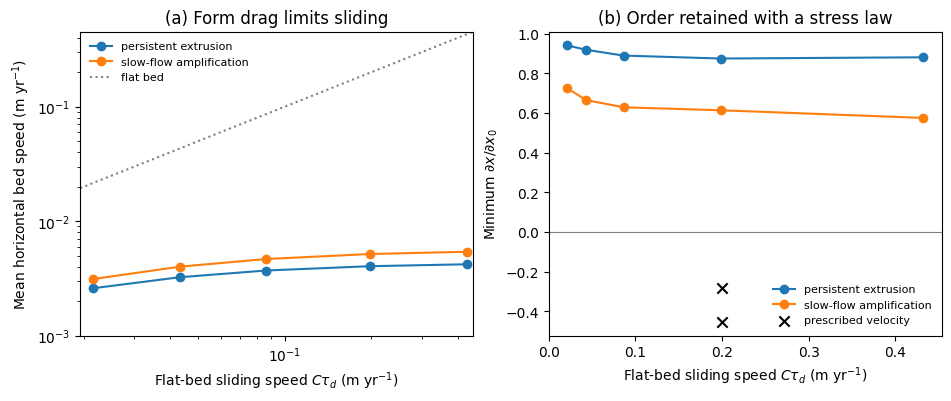

Saved figures:
  ../figures/Figure6.eps
  ../figures/Figure6.pdf
  ../figures/linear_sliding_law_test.png


In [1]:
%matplotlib inline
"""Test the steady fold examples with a linear basal sliding law."""

from pathlib import Path
import logging
import warnings

warnings.filterwarnings("ignore", message="Unable to import recommended hash")
warnings.filterwarnings("ignore", message="The .*Function.at.* method")
logging.getLogger("tsfc").setLevel(logging.ERROR)

import firedrake as fd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.integrate import solve_ivp

plt.rcParams["ps.fonttype"] = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda value: f"{value:.6g}")


LENGTH = 800.0
THICKNESS = 160.0
DENSITY = 917.0
GRAVITY = 9.81
SURFACE_SLOPE = 0.03
VISCOSITY = 2.5e8
PRESCRIBED_SPEED = 0.20
NITSCHE_PENALTY = 3.0e4

CASES = [
    {
        "name": "persistent extrusion",
        "amplitude": 150.0,
        "width_left": 300.0,
        "width_right": 80.0,
        "prescribed_sources": (400.0, 520.0),
        "sliding_law_sources": (420.0, 680.0),
        "target_age": 2500.0,
    },
    {
        "name": "slow-flow amplification",
        "amplitude": 140.0,
        "width_left": 45.0,
        "width_right": 260.0,
        "prescribed_sources": (140.0, 220.0),
        "sliding_law_sources": (440.0, 740.0),
        "target_age": 800.0,
    },
]

MOBILITIES = np.array([0.5e-6, 1.0e-6, 2.0e-6, 4.6e-6, 10.0e-6])
COARSE_MESH = (64, 14)
MESHES = [(64, 14), (96, 21), (128, 28)]
MAXIMUM_AGE = 300_000.0


def bed_profile(x, case):
    """Raised-cosine bed obstacle, repeated with the model period."""
    distance = (np.asarray(x) - 0.5 * LENGTH + 0.5 * LENGTH) % LENGTH - 0.5 * LENGTH
    bed = np.zeros_like(distance, dtype=float)
    left = (distance >= -case["width_left"]) & (distance <= 0.0)
    right = (distance > 0.0) & (distance <= case["width_right"])
    bed[left] = 0.5 * case["amplitude"] * (
        1.0 + np.cos(np.pi * distance[left] / case["width_left"])
    )
    bed[right] = 0.5 * case["amplitude"] * (
        1.0 + np.cos(np.pi * distance[right] / case["width_right"])
    )
    return bed


def bed_slope_expression(x, case):
    """Analytical slope of the raised-cosine bed."""
    distance = x - 0.5 * LENGTH
    left = fd.And(distance >= -case["width_left"], distance <= 0.0)
    right = fd.And(distance > 0.0, distance <= case["width_right"])
    left_slope = -0.5 * case["amplitude"] * np.pi / case["width_left"] * fd.sin(
        np.pi * distance / case["width_left"]
    )
    right_slope = -0.5 * case["amplitude"] * np.pi / case["width_right"] * fd.sin(
        np.pi * distance / case["width_right"]
    )
    return fd.conditional(left, left_slope, fd.conditional(right, right_slope, 0.0))


def represented_bed(x, case, nx):
    """Piecewise-linear bed represented on a mesh with nx divisions."""
    mesh_x = np.linspace(0.0, LENGTH, nx, endpoint=False)
    mesh_bed = bed_profile(mesh_x, case)
    return np.interp(
        np.mod(x, LENGTH),
        np.r_[mesh_x, LENGTH],
        np.r_[mesh_bed, mesh_bed[0]],
    )


def make_mesh(case, nx, nz):
    mesh = fd.PeriodicRectangleMesh(nx, nz, LENGTH, THICKNESS, direction="x")
    reference = mesh.coordinates.dat.data_ro.copy()
    sigma = reference[:, 1] / THICKNESS
    bed = bed_profile(reference[:, 0], case)
    mesh.coordinates.dat.data[:, 1] = bed + sigma * (THICKNESS - bed)
    mesh.clear_spatial_index()
    return mesh


def stokes_forms(mesh):
    velocity_space = fd.VectorFunctionSpace(mesh, "CG", 2)
    pressure_space = fd.FunctionSpace(mesh, "CG", 1)
    mixed_space = velocity_space * pressure_space
    solution = fd.Function(mixed_space)
    velocity_symbol, pressure_symbol = fd.split(solution)
    test_velocity, test_pressure = fd.TestFunctions(mixed_space)
    body_force = fd.Constant(
        (
            DENSITY * GRAVITY * np.sin(SURFACE_SLOPE),
            -DENSITY * GRAVITY * np.cos(SURFACE_SLOPE),
        )
    )
    strain = fd.sym(fd.grad(velocity_symbol))
    residual = (
        2.0 * VISCOSITY * fd.inner(strain, fd.sym(fd.grad(test_velocity)))
        - pressure_symbol * fd.div(test_velocity)
        - test_pressure * fd.div(velocity_symbol)
        - fd.dot(body_force, test_velocity)
    ) * fd.dx
    return mixed_space, solution, velocity_symbol, pressure_symbol, test_velocity, test_pressure, body_force, residual


SOLVER_PARAMETERS = {
    "ksp_type": "preonly",
    "pc_type": "lu",
    "pc_factor_mat_solver_type": "mumps",
}


def finish_solution(mesh, solution):
    velocity, pressure = solution.subfunctions
    pressure.dat.data[:] -= np.mean(pressure.dat.data_ro)
    gradient_space = fd.TensorFunctionSpace(mesh, "DG", 1)
    velocity_gradient = fd.Function(gradient_space).interpolate(fd.grad(velocity))
    return velocity, pressure, velocity_gradient


def solve_prescribed_velocity(case, nx, nz):
    """Reproduce the published prescribed basal-velocity end member."""
    mesh = make_mesh(case, nx, nz)
    mixed_space, solution, u, p, v, q, body_force, residual = stokes_forms(mesh)
    x = fd.SpatialCoordinate(mesh)[0]
    basal_velocity = fd.as_vector(
        (PRESCRIBED_SPEED, PRESCRIBED_SPEED * bed_slope_expression(x, case))
    )
    bed_condition = fd.DirichletBC(mixed_space.sub(0), basal_velocity, 1)
    solution.sub(0).interpolate(fd.Constant((PRESCRIBED_SPEED, 0.0)))
    fd.solve(
        residual == 0,
        solution,
        bcs=[bed_condition],
        solver_parameters=SOLVER_PARAMETERS,
    )
    velocity, pressure, velocity_gradient = finish_solution(mesh, solution)
    normal = fd.FacetNormal(mesh)
    tangent = fd.as_vector((-normal[1], normal[0]))
    stress = 2.0 * VISCOSITY * fd.sym(fd.grad(velocity)) - pressure * fd.Identity(2)
    tangential_traction = fd.dot(stress * normal, tangent)
    tangential_speed = fd.dot(velocity, tangent)
    bed_power = fd.assemble(tangential_traction * tangential_speed * fd.ds(1))
    gravity_power = fd.assemble(fd.dot(body_force, velocity) * fd.dx)
    bed_length = fd.assemble(fd.Constant(1.0) * fd.ds(1, domain=mesh))
    diagnostics = {
        "mean bed x speed": fd.assemble(velocity[0] * fd.ds(1))
        / bed_length,
        "rms normal speed": np.sqrt(
            fd.assemble(fd.dot(velocity, normal) ** 2 * fd.ds(1)) / bed_length
        ),
        "basal power / gravity power": bed_power / gravity_power,
    }
    return mesh, velocity, velocity_gradient, diagnostics


def solve_linear_sliding(case, nx, nz, mobility, penalty=NITSCHE_PENALTY):
    """Solve Stokes flow with u_t = mobility * tau_b and no penetration."""
    mesh = make_mesh(case, nx, nz)
    mixed_space, solution, u, p, v, q, body_force, residual = stokes_forms(mesh)
    normal = fd.FacetNormal(mesh)
    tangent = fd.as_vector((-normal[1], normal[0]))
    cell_size = fd.CellDiameter(mesh)
    identity = fd.Identity(2)
    stress = 2.0 * VISCOSITY * fd.sym(fd.grad(u)) - p * identity
    test_stress = 2.0 * VISCOSITY * fd.sym(fd.grad(v)) - q * identity
    normal_speed = fd.dot(u, normal)
    test_normal_speed = fd.dot(v, normal)
    friction = 1.0 / mobility
    residual += (
        friction * fd.dot(u, tangent) * fd.dot(v, tangent)
        - fd.dot(stress * normal, normal) * test_normal_speed
        - fd.dot(test_stress * normal, normal) * normal_speed
        + penalty * VISCOSITY / cell_size * normal_speed * test_normal_speed
    ) * fd.ds(1)
    fd.solve(residual == 0, solution, solver_parameters=SOLVER_PARAMETERS)
    velocity, pressure, velocity_gradient = finish_solution(mesh, solution)
    bed_length = fd.assemble(fd.Constant(1.0) * fd.ds(1, domain=mesh))
    rms_normal_speed = np.sqrt(
        fd.assemble(fd.dot(velocity, normal) ** 2 * fd.ds(1)) / bed_length
    )
    tangential_speed = fd.dot(velocity, tangent)
    bed_power = -fd.assemble(friction * tangential_speed**2 * fd.ds(1))
    gravity_power = fd.assemble(fd.dot(body_force, velocity) * fd.dx)
    diagnostics = {
        "mean bed x speed": fd.assemble(velocity[0] * fd.ds(1)) / bed_length,
        "rms normal speed": rms_normal_speed,
        "basal power / gravity power": bed_power / gravity_power,
    }
    return mesh, velocity, velocity_gradient, diagnostics


def make_sampler(case, nx, velocity, velocity_gradient=None):
    """Resample a finite-element solution for trajectory integration."""
    horizontal_samples = 241
    vertical_samples = 100
    x = np.linspace(0.0, LENGTH, horizontal_samples, endpoint=False)
    x_evaluation = x.copy()
    x_evaluation[0] = 1.0e-6
    sigma = np.linspace(0.002, 0.99999, vertical_samples)
    bed = represented_bed(x, case, nx)
    X = np.tile(x_evaluation, (len(sigma), 1))
    Z = bed[None, :] + sigma[:, None] * (THICKNESS - bed)[None, :]
    points = np.column_stack((X.ravel(), Z.ravel()))
    velocity_values = np.asarray(velocity.at(points, tolerance=1.0e-7)).reshape(
        Z.shape + (2,)
    )
    fields = {"u": velocity_values[..., 0], "w": velocity_values[..., 1]}
    if velocity_gradient is not None:
        gradient_values = np.asarray(
            velocity_gradient.at(points, tolerance=1.0e-7)
        ).reshape(Z.shape + (2, 2))
        fields["uz"] = gradient_values[..., 0, 1]
    dx = LENGTH / len(x)
    dsigma = sigma[1] - sigma[0]

    def sample(x_position, z_position, names=("u", "w")):
        x_wrapped = np.mod(x_position, LENGTH)
        local_bed = float(represented_bed(np.array([x_wrapped]), case, nx)[0])
        local_sigma = (z_position - local_bed) / (THICKNESS - local_bed)
        if not names:
            return {"sigma": local_sigma}
        x_index = x_wrapped / dx
        ix0 = int(np.floor(x_index)) % len(x)
        ix1 = (ix0 + 1) % len(x)
        x_weight = x_index - np.floor(x_index)
        sigma_index = (local_sigma - sigma[0]) / dsigma
        iz0 = int(np.clip(np.floor(sigma_index), 0, len(sigma) - 2))
        iz1 = iz0 + 1
        sigma_weight = np.clip(sigma_index - iz0, 0.0, 1.0)
        output = {}
        for name in names:
            values = fields[name]
            lower = (1.0 - x_weight) * values[iz0, ix0] + x_weight * values[iz0, ix1]
            upper = (1.0 - x_weight) * values[iz1, ix0] + x_weight * values[iz1, ix1]
            output[name] = float((1.0 - sigma_weight) * lower + sigma_weight * upper)
        return output | {"sigma": local_sigma}

    return sample


def integrate_path(sample, case, nx, x0, maximum_age):
    """Trace one particle from the deposition surface until it re-emerges."""
    start_sigma = 0.9999
    start_bed = float(represented_bed(np.array([x0]), case, nx)[0])
    z0 = start_bed + start_sigma * (THICKNESS - start_bed)
    surface = sample(x0, z0)

    def right_hand_side(time, state):
        values = sample(state[0], state[1])
        return [values["u"], values["w"]]

    def surface_return(time, state):
        if time < 10.0:
            return -1.0
        return sample(state[0], state[1], names=())["sigma"] - 0.99995

    surface_return.terminal = True
    surface_return.direction = 1
    path = solve_ivp(
        right_hand_side,
        (0.0, maximum_age),
        [x0, z0],
        rtol=1.0e-7,
        atol=1.0e-9,
        max_step=250.0,
        events=[surface_return],
        dense_output=True,
    )
    return {
        "x0": x0,
        "path": path,
        "accumulation": -surface["w"],
        "surface_speed": surface["u"],
    }


def trace_sources(sample, case, nx, source_limits, maximum_age, count=61):
    source_x = np.linspace(*source_limits, count)
    return [
        integrate_path(sample, case, nx, x0, maximum_age)
        for x0 in source_x
    ]


def order_at_age(traces, age):
    """Return the smallest neighboring-source Jacobian at one age."""
    source_x = np.array([trace["x0"] for trace in traces])
    positions = np.full((len(traces), 2), np.nan)
    for index, trace in enumerate(traces):
        if trace["accumulation"] > 0.0 and age <= trace["path"].t[-1]:
            positions[index] = trace["path"].sol(age)
    valid = np.isfinite(positions[:, 0])
    valid_indices = np.where(valid)[0]
    groups = np.split(valid_indices, np.where(np.diff(valid_indices) > 1)[0] + 1)
    derivatives = []
    for group in groups:
        if len(group) >= 5:
            derivatives.append(
                np.gradient(positions[group, 0], source_x[group])
            )
    if not derivatives:
        return np.nan
    return min(np.min(derivative) for derivative in derivatives)


def minimum_order_during_residence(traces, maximum_age):
    ages = np.linspace(0.0, maximum_age, 121)
    values = np.array([order_at_age(traces, age) for age in ages])
    if np.all(~np.isfinite(values)):
        return np.nan, np.nan
    index = np.nanargmin(values)
    return values[index], ages[index]


def driving_stress():
    return DENSITY * GRAVITY * THICKNESS * np.sin(SURFACE_SLOPE)


def flat_bed_speed(mobility):
    return mobility * driving_stress()


print("The flat-bed driving stress is", round(driving_stress(), 1), "Pa.")
flat_case = {
    "name": "flat-bed validation",
    "amplitude": 0.0,
    "width_left": 300.0,
    "width_right": 80.0,
}
_, _, _, flat_diagnostics = solve_linear_sliding(
    flat_case, *COARSE_MESH, mobility=4.6e-6
)
flat_exact = flat_bed_speed(4.6e-6)
flat_error = (flat_diagnostics["mean bed x speed"] - flat_exact) / flat_exact
print(
    "Flat-bed validation at C=4.6e-6 m yr-1 Pa-1:",
    f"FEM={flat_diagnostics['mean bed x speed']:.9f} m yr-1,",
    f"exact={flat_exact:.9f} m yr-1,",
    f"relative error={flat_error:.2e}.",
)
print("Solving prescribed-velocity controls.")
control_rows = []
power_convergence_rows = []
for case in CASES:
    for nx, nz in MESHES:
        mesh, velocity, gradient, diagnostics = solve_prescribed_velocity(case, nx, nz)
        power_convergence_rows.append(
            {
                "case": case["name"],
                "mesh": f"{nx} x {nz}",
                "basal power / gravity power": diagnostics[
                    "basal power / gravity power"
                ],
                "rms normal speed": diagnostics["rms normal speed"],
            }
        )
        if (nx, nz) != COARSE_MESH:
            continue
        sample = make_sampler(case, nx, velocity)
        traces = trace_sources(
            sample,
            case,
            nx,
            case["prescribed_sources"],
            case["target_age"],
            count=81,
        )
        control_rows.append(
            {
                "case": case["name"],
                "boundary": "prescribed velocity",
                "mobility": np.nan,
                "flat-bed speed": PRESCRIBED_SPEED,
                "mean bed x speed": diagnostics["mean bed x speed"],
                "minimum dx/dx0": order_at_age(traces, case["target_age"]),
                "age of minimum": case["target_age"],
                "rms normal speed": diagnostics["rms normal speed"],
                "basal power / gravity power": diagnostics[
                    "basal power / gravity power"
                ],
            }
        )

print("Solving the linear sliding-law mobility sweep.")
sweep_rows = []
saved_fine_inputs = {}
for case in CASES:
    nx, nz = COARSE_MESH
    for mobility in MOBILITIES:
        print(f"  {case['name']}, C={mobility:.1e} m yr-1 Pa-1", flush=True)
        mesh, velocity, gradient, diagnostics = solve_linear_sliding(
            case, nx, nz, mobility
        )
        sample = make_sampler(case, nx, velocity)
        traces = trace_sources(
            sample,
            case,
            nx,
            case["sliding_law_sources"],
            MAXIMUM_AGE,
        )
        minimum_order, age_of_minimum = minimum_order_during_residence(
            traces, MAXIMUM_AGE
        )
        sweep_rows.append(
            {
                "case": case["name"],
                "boundary": "linear sliding law",
                "mobility": mobility,
                "flat-bed speed": flat_bed_speed(mobility),
                "mean bed x speed": diagnostics["mean bed x speed"],
                "minimum dx/dx0": minimum_order,
                "age of minimum": age_of_minimum,
                "rms normal speed": diagnostics["rms normal speed"],
                "basal power / gravity power": diagnostics[
                    "basal power / gravity power"
                ],
            }
        )

controls = pd.DataFrame(control_rows)
power_convergence = pd.DataFrame(power_convergence_rows)
sweep = pd.DataFrame(sweep_rows)
display(controls)
display(power_convergence)
display(sweep)


print("Checking the sign on three meshes at C=4.6e-6 m yr-1 Pa-1.")
convergence_rows = []
for case in CASES:
    for nx, nz in MESHES:
        print(f"  {case['name']}, mesh {nx} x {nz}", flush=True)
        mesh, velocity, gradient, diagnostics = solve_linear_sliding(
            case, nx, nz, 4.6e-6
        )
        sample = make_sampler(case, nx, velocity)
        traces = trace_sources(
            sample,
            case,
            nx,
            case["sliding_law_sources"],
            MAXIMUM_AGE,
        )
        minimum_order, age_of_minimum = minimum_order_during_residence(
            traces, MAXIMUM_AGE
        )
        convergence_rows.append(
            {
                "case": case["name"],
                "mesh": f"{nx} x {nz}",
                "minimum dx/dx0": minimum_order,
                "age of minimum": age_of_minimum,
                "mean bed x speed": diagnostics["mean bed x speed"],
                "rms normal speed": diagnostics["rms normal speed"],
            }
        )

convergence = pd.DataFrame(convergence_rows)
display(convergence)


fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9), constrained_layout=True)
for case in CASES:
    group = sweep[sweep["case"] == case["name"]]
    axes[0].plot(
        group["flat-bed speed"],
        group["mean bed x speed"],
        marker="o",
        label=case["name"],
    )
    axes[1].plot(
        group["flat-bed speed"],
        group["minimum dx/dx0"],
        marker="o",
        label=case["name"],
    )
limit = 1.05 * sweep["flat-bed speed"].max()
minimum_speed = 0.9 * sweep["flat-bed speed"].min()
axes[0].plot(
    [minimum_speed, limit],
    [minimum_speed, limit],
    color="0.5",
    linestyle=":",
    label="flat bed",
)
axes[0].set(
    xlabel=r"Flat-bed sliding speed $C\tau_d$ (m yr$^{-1}$)",
    ylabel=r"Mean horizontal bed speed (m yr$^{-1}$)",
    title="(a) Form drag limits sliding",
    xscale="log",
    yscale="log",
    xlim=(minimum_speed, limit),
    ylim=(1.0e-3, limit),
)
axes[1].axhline(0.0, color="0.5", linewidth=0.8)
for index, (_, row) in enumerate(controls.iterrows()):
    axes[1].scatter(
        PRESCRIBED_SPEED,
        row["minimum dx/dx0"],
        marker="x",
        s=55,
        color="black",
        zorder=4,
        label="prescribed velocity" if index == 0 else None,
    )
axes[1].set(
    xlabel=r"Flat-bed sliding speed $C\tau_d$ (m yr$^{-1}$)",
    ylabel=r"Minimum $\partial x/\partial x_0$",
    title="(b) Order retained with a stress law",
    xlim=(0.0, limit),
)
axes[0].legend(frameon=False, fontsize=8)
axes[1].legend(frameon=False, fontsize=8, loc="lower right")

figure_directory = Path("figures") if Path("figures").exists() else Path("../figures")
figure_directory.mkdir(exist_ok=True)
eps_path = figure_directory / "Figure6.eps"
pdf_path = figure_directory / "Figure6.pdf"
png_path = figure_directory / "linear_sliding_law_test.png"
fig.savefig(eps_path)
fig.savefig(pdf_path)
fig.savefig(png_path, dpi=220)
plt.show()

print("Saved figures:")
print(" ", eps_path)
print(" ", pdf_path)
print(" ", png_path)


## Interpretation

**Calculation.** The flat-bed finite-element speed agrees with $C\tau_d$ to machine precision. Over the two large obstacles, form drag limits mean basal speed to 0.0026--0.0054 m yr$^{-1}$ even though the same mobilities predict 0.022--0.432 m yr$^{-1}$ over a flat bed. The order Jacobian remains positive over the full surface residence: its minima are 0.875--0.941 for persistent extrusion and 0.576--0.724 for slow-flow amplification. At $C=4.6\times10^{-6}$, the fine-mesh values are 0.891 and 0.585.

**Mechanical inference.** The passive linear law does not reproduce either fold. Lower mobility preserves more order rather than giving a slower version of the prescribed-speed result. The prescribed boundary instead requires positive basal work equal to about 34--35 and 102--114 times the gravity power across the three meshes. Those folds are therefore driven by the imposed moving boundary.

**Scope.** This is a negative test of the same two idealized geometries, not a universal no-folding result for stress-dependent sliding. Different geometry, rheology or traction structure could still produce a steady trajectory whose order budget crosses zero.